# **Eliminación backward con elastic net y AIC**

Se parte del diseño completo de elastic net (el de M3_joint: género,
covariables, las tres dimensiones del apoyo y sus interacciones con el género)
y se eliminan variables una a una:

1. Se empieza con todas las variables predictoras.
2. Se ajusta elastic net eligiendo α y λ por validación cruzada: para cada α
   se corre `cv.glmnet()` y se queda la combinación con menor error de CV
   (`lambda.min`).
3. Si ningún coeficiente queda exactamente en cero, el proceso se detiene.
4. Entre las variables con coeficiente cero, sale la que deja el menor AIC al
   retirarla. Para cada candidata se reajusta el paso 2 sin ella y se calcula
   el AIC del propio elastic net:
   $\text{AIC} = -2 \log L + 2k$, con $k$ = coeficientes distintos de cero
   más el intercepto.
5. Se vuelve al paso 2 con el modelo reducido, eligiendo α y λ desde cero.

Cada "variable" es una columna del diseño: los factores aportan una dummy por
nivel no referencia, que puede salir por separado. $\log L$ es la
verosimilitud gaussiana con $\hat\sigma^2 = \text{RSS}/n$, evaluada en las
predicciones del elastic net. Todos los ajustes usan los mismos 10 folds,
estratificados por género, para que los errores de CV sean comparables entre
pasos.

## *Carga de paquetes y configuración*

In [1]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(gt)
})

# Parche para que las tablas gt se vean en Jupyter (mismo del EDA)
repr_html.gt_tbl <- function(obj, ...) gt::as_raw_html(obj)
repr_markdown.gt_tbl <- function(obj, ...) NULL
repr_latex.gt_tbl <- function(obj, ...) NULL
for (g in c("repr_html", "repr_markdown", "repr_latex")) {
  registerS3method(g, "gt_tbl", get(paste0(g, ".gt_tbl")), envir = asNamespace("repr"))
}

# Las rutas de config.R son relativas a la raíz del proyecto.
if (!file.exists("myst.yml") && file.exists("../myst.yml")) setwd("..")

if (file.exists(".Renviron")) readRenviron(".Renviron")

source("R/config.R")
source("R/data_prep.R")
source("R/moderation_pipeline.R")
source("R/cross_validation.R")
source("R/elastic_net.R")
source("R/backward_en.R")

col_morado <- viridisLite::viridis(10, end = 0.8)[1]
col_verde  <- viridisLite::viridis(10, end = 0.8)[10]

## *Datos y diseño*

Muestra analítica de 530 casos, con el apoyo centrado en la gran media y el
género codificado como en los modelos jerárquicos.

In [2]:
model_data <- build_analytic_sample()
design     <- build_en_design(model_data)

set.seed(SEED)
foldid <- assign_stratified_folds(model_data[[CV_STRATA_VAR]], EN_INNER_FOLDS)

cat(sprintf("Casos:      %d\n", nrow(design$x)))
cat(sprintf("Variables:  %d\n", ncol(design$x)))
cat(sprintf("Respuesta:  %s (%s)\n", OUTCOME_VAR,
            if (is_binary_outcome(design$y)) "binaria" else "continua"))
cat(sprintf("α evaluados: %s\n", paste(EN_ALPHAS, collapse = ", ")))

tibble(Variable = colnames(design$x)) %>%
  gt() %>%
  tab_header(title = "Variables del modelo completo")

Casos:      530
Variables:  14
Respuesta:  Entrapment (continua)
α evaluados: 0.1, 0.25, 0.5, 0.75, 1


<div id="nskdlujivt" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#nskdlujivt table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#nskdlujivt thead, #nskdlujivt tbody, #nskdlujivt tfoot, #nskdlujivt tr, #nskdlujivt td, #nskdlujivt th {
  border-style: none;
}

#nskdlujivt p {
  margin: 0;
  padding: 0;
}

#nskdlujivt .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#nskdlujivt .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#nskdlujivt .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#nskdlujivt .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#nskdlujivt .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#nskdlujivt .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#nskdlujivt .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#nskdlujivt .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#nskdlujivt .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#nskdlujivt .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#nskdlujivt .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#nskdlujivt .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#nskdlujivt .gt_spanner_row {
  border-bottom-style: hidden;
}

#nskdlujivt .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *Eliminación backward*

In [3]:
res <- backward_en(design$x, design$y, foldid)
steps <- res$steps

Paso  1: sale MunicipalityPuerto Colombia  AIC =  1352.86  ceros = 4
Paso  2: sale EthnicityCaucasian           AIC =  1352.51  ceros = 3
Paso  3: sale Gender_code:Family_c         AIC =  1352.18  ceros = 2
Paso  4: sale SigOthers_c                  AIC =  1353.61  ceros = 0
Fin: ningún coeficiente en cero.


### *Registro de los pasos*

El paso 0 es el modelo completo. En cada paso siguiente, *Eliminada* es la
variable que salió para llegar a ese modelo, y las demás columnas describen el
elastic net reajustado sin ella. RMSE y R² se calculan con las predicciones
fuera de fold de `lambda.min`.

In [4]:
steps %>%
  select(step, n_vars, removed, alpha, lambda, aic, k, n_zero, zero_vars,
         any_of(c("cv_rmse", "cv_r2", "cv_auc", "cv_accuracy"))) %>%
  gt() %>%
  fmt_number(c(lambda, aic), decimals = 4) %>%
  fmt_number(any_of(c("cv_rmse", "cv_r2", "cv_auc", "cv_accuracy")), decimals = 4) %>%
  sub_missing(missing_text = "—") %>%
  cols_label(step = "Paso", n_vars = "Variables", removed = "Eliminada",
             alpha = "α", lambda = "λ", aic = "AIC", k = "k",
             n_zero = "Coef. en cero", zero_vars = "Variables en cero",
             cv_rmse = "RMSE (CV)", cv_r2 = "R² (CV)") %>%
  tab_style(style = cell_text(weight = "bold"),
            locations = cells_body(rows = aic == min(aic))) %>%
  tab_header(title = "Eliminación backward con elastic net",
             subtitle = "En negrita, el paso con menor AIC")

<div id="uerbosnpxv" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#uerbosnpxv table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#uerbosnpxv thead, #uerbosnpxv tbody, #uerbosnpxv tfoot, #uerbosnpxv tr, #uerbosnpxv td, #uerbosnpxv th {
  border-style: none;
}

#uerbosnpxv p {
  margin: 0;
  padding: 0;
}

#uerbosnpxv .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#uerbosnpxv .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#uerbosnpxv .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#uerbosnpxv .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#uerbosnpxv .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#uerbosnpxv .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#uerbosnpxv .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#uerbosnpxv .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#uerbosnpxv .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#uerbosnpxv .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#uerbosnpxv .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#uerbosnpxv .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#uerbosnpxv .gt_spanner_row {
  border-bottom-style: hidden;
}

#uerbosnpxv .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Candidatas evaluadas en cada paso*

AIC del elastic net reajustado sin cada variable con coeficiente cero. Sale la
de menor AIC.

In [5]:
res$candidates %>%
  group_by(step) %>%
  mutate(sale = aic == min(aic)) %>%
  ungroup() %>%
  gt(groupname_col = "step") %>%
  fmt_number(aic, decimals = 4) %>%
  text_transform(locations = cells_body(columns = sale),
                 fn = function(x) ifelse(x == "TRUE", "sí", "")) %>%
  cols_label(candidate = "Candidata", aic = "AIC sin ella", sale = "Sale") %>%
  tab_header(title = "Candidatas por paso")

<div id="xmnemctwjr" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#xmnemctwjr table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#xmnemctwjr thead, #xmnemctwjr tbody, #xmnemctwjr tfoot, #xmnemctwjr tr, #xmnemctwjr td, #xmnemctwjr th {
  border-style: none;
}

#xmnemctwjr p {
  margin: 0;
  padding: 0;
}

#xmnemctwjr .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#xmnemctwjr .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#xmnemctwjr .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#xmnemctwjr .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#xmnemctwjr .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#xmnemctwjr .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#xmnemctwjr .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#xmnemctwjr .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#xmnemctwjr .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#xmnemctwjr .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#xmnemctwjr .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#xmnemctwjr .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#xmnemctwjr .gt_spanner_row {
  border-bottom-style: hidden;
}

#xmnemctwjr .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *AIC por paso*

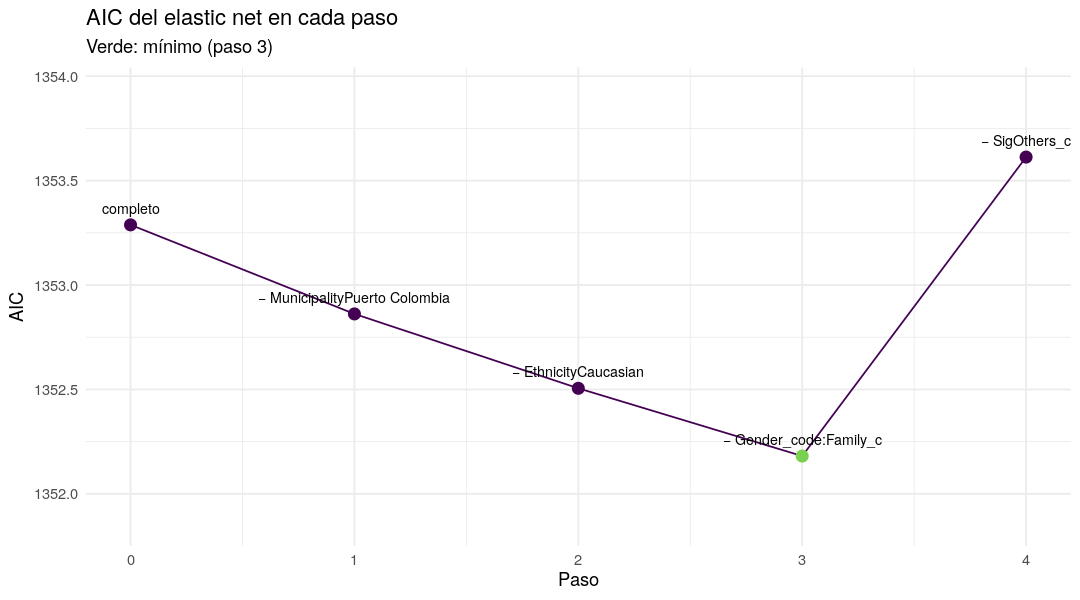

In [6]:
options(repr.plot.width = 9, repr.plot.height = 5)

paso_min <- steps$step[which.min(steps$aic)]

ggplot(steps, aes(x = step, y = aic)) +
  geom_line(color = col_morado) +
  geom_point(aes(color = step == paso_min), size = 3, show.legend = FALSE) +
  geom_text(aes(label = ifelse(is.na(removed), "completo", paste("−", removed))),
            vjust = -1, size = 3) +
  scale_color_manual(values = c(`FALSE` = col_morado, `TRUE` = col_verde)) +
  scale_x_continuous(breaks = steps$step) +
  scale_y_continuous(expand = expansion(mult = 0.3)) +
  labs(title = "AIC del elastic net en cada paso",
       subtitle = sprintf("Verde: mínimo (paso %d)", paso_min),
       x = "Paso", y = "AIC") +
  theme_minimal()

## *Modelo final*

In [7]:
final <- res$fits[[paso_min + 1]]

cat(sprintf("AIC mínimo en el paso %d: %.4f (α = %g, λ = %.4f)\n",
            paso_min, final$aic, final$alpha, final$lambda))
cat(sprintf("Variables en el modelo: %d, de las cuales %d tienen coeficiente distinto de cero\n",
            length(final$vars), sum(final$coef != 0)))

tibble(Variable = names(final$coef), Coeficiente = unname(final$coef)) %>%
  mutate(Estado = ifelse(Coeficiente == 0, "en cero", "")) %>%
  gt() %>%
  fmt_number(Coeficiente, decimals = 4) %>%
  tab_header(title = sprintf("Variables del modelo final (paso %d)", paso_min),
             subtitle = sprintf("α = %g, λ = %.4f", final$alpha, final$lambda))

AIC mínimo en el paso 3: 1352.1810 (α = 0.25, λ = 0.0429)
Variables en el modelo: 11, de las cuales 9 tienen coeficiente distinto de cero


<div id="qxfcneiwkn" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#qxfcneiwkn table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#qxfcneiwkn thead, #qxfcneiwkn tbody, #qxfcneiwkn tfoot, #qxfcneiwkn tr, #qxfcneiwkn td, #qxfcneiwkn th {
  border-style: none;
}

#qxfcneiwkn p {
  margin: 0;
  padding: 0;
}

#qxfcneiwkn .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#qxfcneiwkn .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#qxfcneiwkn .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#qxfcneiwkn .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#qxfcneiwkn .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#qxfcneiwkn .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#qxfcneiwkn .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#qxfcneiwkn .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#qxfcneiwkn .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#qxfcneiwkn .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#qxfcneiwkn .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#qxfcneiwkn .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#qxfcneiwkn .gt_spanner_row {
  border-bottom-style: hidden;
}

#qxfcneiwkn .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

El proceso hace cuatro eliminaciones y se detiene en el paso 4, cuando ya no
queda ningún coeficiente en cero. El AIC baja en los tres primeros pasos, al
quitar `MunicipalityPuerto Colombia`, `EthnicityCaucasian` y
`Gender_code:Family_c`, y llega a su **mínimo en el paso 3** (AIC = 1352.18,
α = 0.25, λ = 0.043). Al quitar después `SigOthers_c` sube a 1353.61.

El modelo final tiene 11 variables, y 9 de ellas tienen coeficiente distinto
de cero: género, Santo Tomás y Suan, SSE Medium-High, etnia afrodescendiente y
Other, apoyo familiar, apoyo de amigos y la interacción
`Gender_code:SigOthers_c`. `SigOthers_c` y `Gender_code:Friends_c` siguen en el
modelo, pero con coeficiente cero.

Hay que tener en cuenta tres cosas:

- **Las diferencias de AIC son muy pequeñas.** Entre el paso con mayor AIC y el
  de menor hay 1.4 puntos, por debajo de 2, que es la diferencia mínima que
  suele considerarse relevante. El error de CV casi no cambia (RMSE entre 0.869
  y 0.870; R² entre 0.190 y 0.193). En la práctica, todos los pasos predicen lo
  mismo.
- **El modelo final no respeta la jerarquía de los términos.** Deja la
  interacción `Gender_code:SigOthers_c` con un coeficiente de 0.051 mientras el
  efecto principal `SigOthers_c` vale cero. Eso dificulta interpretar la
  interacción.
- **Las dummies de un factor salen por separado.** Por ejemplo, sale Puerto
  Colombia pero quedan Santo Tomás y Suan. Así, Puerto Colombia pasa a
  compararse junto con la categoría de referencia (Polo Nuevo).

## *Guardado*

- `outputs/tables/backward_en_steps.csv`: registro de los pasos.

In [8]:
dir.create(dirname(PATH_BACKWARD_EN), showWarnings = FALSE, recursive = TRUE)
steps %>%
  mutate(vars = map_chr(vars, paste, collapse = " + "),
         nonzero = map_chr(nonzero, paste, collapse = " + ")) %>%
  write_csv(PATH_BACKWARD_EN)
cat(PATH_BACKWARD_EN, "\n")

outputs/tables/backward_en_steps.csv 
